# Lab 4: Knowledge Representation & Logical Reasoning



## 1. Introduction to Knowledge Representation

Knowledge Representation (KR) is the process of storing real-world information in a structured format so that an AI system can understand it, reason about it, and make decisions.

For example, consider these facts:

- A dog is an animal.
- Bruno is a dog.
- Every animal needs food.

An AI system can use these facts to infer:

Bruno needs food.

This is the basic idea of knowledge representation: storing facts and using logical rules to derive new information.

### Main components

| Component     | Meaning                                        |
| ------------- | ---------------------------------------------- |
| Facts         | Information known to be true                   |
| Rules         | Conditions used to derive conclusions          |
| Objects       | Real-world entities                            |
| Relationships | Connections between entities                   |
| Inference     | Deriving new knowledge from existing knowledge |



## Practical 1: Rule-Based Knowledge Representation

A Rule-Based System represents knowledge using IF-THEN rules.

For example:

```
IF temperature is high
THEN weather is hot
```

The system checks whether the condition is true and then executes the corresponding action.

In [1]:
# Rule-Based Knowledge Representation

facts = {
    "temperature_high": True,
    "humidity_high": True,
    "cloudy": False
}

rules = [
    {
        "condition": "temperature_high",
        "result": "Weather is hot"
    },
    {
        "condition": "humidity_high",
        "result": "Humidity is high"
    },
    {
        "condition": "cloudy",
        "result": "It may rain"
    }
]

print("Knowledge Base Results:\n")

for rule in rules:
    if facts.get(rule["condition"], False):
        print("IF", rule["condition"],
              "THEN", rule["result"])

Knowledge Base Results:

IF temperature_high THEN Weather is hot
IF humidity_high THEN Humidity is high


## Practical 2: Predicate Logic Representation

Predicate Logic is a way of representing knowledge using objects, properties, and relationships. It is more expressive than simple IF-THEN rules because it can represent statements about multiple objects.

### 1. Basic components

| Component | Meaning                      | Example                                |
| --------- | ---------------------------- | -------------------------------------- |
| Predicate | Property or relationship     | `Student(Abdul)`                       |
| Constant  | A specific object            | `Abdul`                                |
| Variable  | Represents an unknown object | `X`                                    |
| Fact      | A statement considered true  | `Studies(Abdul)`                       |
| Rule      | A logical condition          | If someone studies, they are a student |

### 2. Logical quantifiers

There are two important quantifiers:

- Universal quantifier (∀): Means "For all".
- Existential quantifier (∃): Means "There exists at least one".

Examples:

1\. Every student studies:

\\[ \forall x \\; (Student(x) \rightarrow Studies(x)) \\]

2\. At least one student plays cricket:

\\[ \exists x \\; (Student(x) \land PlaysCricket(x)) \\]

In [2]:
# Predicate Logic Representation

students = ["Abdul", "Rahul", "Aman"]

# Facts
def is_student(name):
    return name in students

def studies(name):
    return is_student(name)

def plays_cricket(name):
    return name == "Rahul"

# Universal quantifier: Every student studies
print("Every student studies:")

for student in students:
    print(student, ":", studies(student))

# Existential quantifier: At least one student plays cricket
result = any(plays_cricket(s) for s in students)

print("\nDoes any student play cricket?", result)

Every student studies:
Abdul : True
Rahul : True
Aman : True

Does any student play cricket? True


## Practical 3: Semantic Networks

A Semantic Network is a graphical method of representing knowledge using nodes and relationships.

- Nodes: Represent objects, people, places, or concepts.
- Edges: Represent relationships between those objects.

For example:

- Dog is an Animal.
- Animal needs Food.
- Bruno is a Dog.

From these relationships, we can understand that Bruno is an animal.

### 1. Common relationships

| Relationship | Meaning                              |
| ------------ | ------------------------------------ |
| IS-A         | Represents inheritance or category   |
| HAS-A        | Represents possession or composition |
| PART-OF      | Represents a component of something  |
| INSTANCE-OF  | Connects an object to its class      |



### 2. Advantages and limitations

Advantages:

- Easy to understand and visualize.
- Shows relationships between concepts.
- Supports inheritance of properties.

Limitations:

- Large networks become complicated.
- Complex logical conditions are difficult to represent.
- Relationship meanings must be clearly defined.


In [4]:
pip install networkx

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.1 MB 5.0 MB/s eta 0:00:01
   ---------------------------------------  2.1/2.1 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 6.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


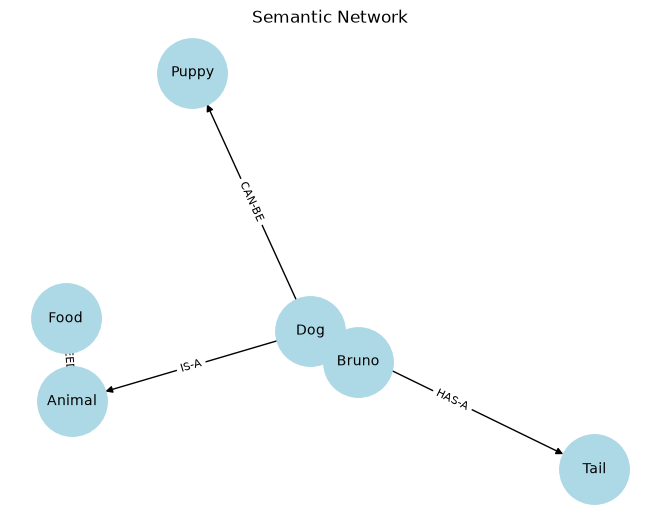

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a directed graph
G = nx.DiGraph()

# Add relationships
relationships = [
    ("Bruno", "Dog", "INSTANCE-OF"),
    ("Dog", "Animal", "IS-A"),
    ("Animal", "Food", "NEEDS"),
    ("Dog", "Tail", "HAS-A"),
    ("Dog", "Puppy", "CAN-BE")
]

for source, target, relation in relationships:
    G.add_edge(source, target, label=relation)

# Draw the network
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightblue",
    node_size=2500,
    font_size=10,
    arrows=True
)

edge_labels = nx.get_edge_attributes(G, "label")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title("Semantic Network")
plt.savefig("outputs/SemanticNetwork.png",
            bbox_inches="tight")
plt.show()

## Practical 4: Frame Representation

A Frame is a knowledge representation technique that stores information about an object, person, or concept in a structured format.

Think of a frame as a form containing different fields (called slots) and their corresponding values.

For example, a student frame might contain:

- Name
- Age
- Course
- College
- Skills

### 1. Components of a Frame

| Component     | Meaning                                                 |
| ------------- | ------------------------------------------------------- |
| Frame         | Represents an object or concept                         |
| Slot          | Represents an attribute                                 |
| Value         | Stores information in a slot                            |
| Default Value | A value used when specific information is unavailable   |
| Inheritance   | Allows a frame to receive properties from another frame |

### 2. Advantages

- Organizes knowledge in a structured format.
- Makes information easy to access and update.
- Supports inheritance and default values.
- Useful for representing real-world objects.



In [6]:
# Frame Representation using Python

student_frame = {
    "Name": "Abdul",
    "Age": 22,
    "Course": "MCA",
    "College": "IIPS",
    "Skills": ["Python", "JavaScript", "React"]
}

# Inherited frame
college_student_frame = {
    "Name": "Rahul",
    "Age": 21,
    "Course": "MCA"
}

# Inherit missing properties from student frame
for slot, value in student_frame.items():
    if slot not in college_student_frame:
        college_student_frame[slot] = value

print("Student Frame:")
for slot, value in student_frame.items():
    print(slot, ":", value)

print("\nCollege Student Frame:")
for slot, value in college_student_frame.items():
    print(slot, ":", value)

Student Frame:
Name : Abdul
Age : 22
Course : MCA
College : IIPS
Skills : ['Python', 'JavaScript', 'React']

College Student Frame:
Name : Rahul
Age : 21
Course : MCA
College : IIPS
Skills : ['Python', 'JavaScript', 'React']


## Practical 5: Conceptual Dependency (CD)

Conceptual Dependency is a knowledge representation technique used to represent the meaning of natural-language sentences in a standard form.

Its main purpose is to represent the actual action or meaning of a sentence, rather than just its words.

For example:

- Rahul gave a book to Aman.
- Rahul transferred a book to Aman.

Both sentences describe the same basic action: transferring possession of a book.

### 1. Main concepts

Conceptual Dependency represents actions using primitive actions and their participants.

Some commonly discussed primitive actions include:

| Primitive | Meaning                             |
| --------- | ----------------------------------- |
| ATRANS    | Transfer of ownership or possession |
| PTRANS    | Physical movement of an object      |
| MTRANS    | Transfer of information             |
| INGEST    | Taking something into the body      |
| PROPEL    | Applying physical force             |
| MOVE      | Moving a body part                  |

### 2. Applications

- Natural Language Processing (NLP)
- Understanding sentence meaning
- Question-answering systems
- Knowledge-based AI systems


In [7]:
# Conceptual Dependency Representation

actions = {
    "Giving": {
        "primitive": "ATRANS",
        "actor": "Rahul",
        "object": "Book",
        "receiver": "Aman",
        "meaning": "Transfer of possession"
    },

    "Going": {
        "primitive": "PTRANS",
        "actor": "Abdul",
        "object": "Person",
        "destination": "College",
        "meaning": "Physical movement"
    },

    "Telling": {
        "primitive": "MTRANS",
        "actor": "Teacher",
        "object": "Information",
        "receiver": "Student",
        "meaning": "Transfer of information"
    }
}

for action, details in actions.items():
    print("\nAction:", action)

    for key, value in details.items():
        print(key, ":", value)


Action: Giving
primitive : ATRANS
actor : Rahul
object : Book
receiver : Aman
meaning : Transfer of possession

Action: Going
primitive : PTRANS
actor : Abdul
object : Person
destination : College
meaning : Physical movement

Action: Telling
primitive : MTRANS
actor : Teacher
object : Information
receiver : Student
meaning : Transfer of information


## Practical 6: Logical Inference

Logical Inference is the process of deriving new information or conclusions from existing facts and rules.

In simple terms, an AI system uses known information and logical rules to reach a conclusion.

### 1. Example

Suppose we have these facts:

1. All humans are mortal.
2. Rahul is a human.

Using logical reasoning, we can conclude:

Rahul is mortal.

This is an example of modus ponens, a basic inference rule.

### 2. Types of logical inference

| Type                | Meaning                                               |
| ------------------- | ----------------------------------------------------- |
| Deductive Reasoning | Derives a specific conclusion from general facts.     |
| Inductive Reasoning | Derives a general pattern from specific observations. |
| Modus Ponens        | If P implies Q, and P is true, then Q is true.        |

### 3. Applications

- Expert systems
- Medical diagnosis systems
- Knowledge-based chatbots
- Automated reasoning
- Decision-support systems


In [8]:
# Logical Inference Engine

facts = {
    "Rahul_is_human": True,
    "Aman_is_human": True,
    "Bruno_is_animal": True
}

# Rules
rules = {
    "Rahul_is_human": "Rahul_is_mortal",
    "Aman_is_human": "Aman_is_mortal",
    "Bruno_is_animal": "Bruno_needs_food"
}

# Inference process
print("Known Facts:")
for fact in facts:
    if facts[fact]:
        print(fact)

print("\nDerived Conclusions:")

for condition, conclusion in rules.items():
    if facts.get(condition, False):
        print(conclusion, "=> True")

Known Facts:
Rahul_is_human
Aman_is_human
Bruno_is_animal

Derived Conclusions:
Rahul_is_mortal => True
Aman_is_mortal => True
Bruno_needs_food => True
